# Bus vs Tube: recovery after COVID

Daily Tube and bus journeys (TfL Network Demand, Jan 2019 - Nov 2026). The EDA showed the Tube
levelling off while buses slip. This notebook measures that properly:

1. Recovery relative to 2019, by year and day of the week.
2. The trend since mid-2023, when both modes had stopped recovering quickly.
3. When the bus decline started (year-on-year change).
4. How much of it service cuts can explain (BUSTO capacity, previous notebook).

Each day is compared with the 2019 mean for the same **month and day of the week**, which removes
seasonality and the weekly cycle. Strikes, bank holidays and Christmas are removed
(`tfl_bus.atypical_days`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

import tfl_bus as B

B.RESULTS.mkdir(parents=True, exist_ok=True)
DOW = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

j = B.load_journeys()
j = j[~j.index.isin(B.atypical_days(j).index)].copy()
j['dow'], j['month'], j['year'] = j.index.dayofweek, j.index.month, j.index.year
base = j[j.year == 2019].groupby(['month', 'dow'])[['tube', 'bus']].mean()
key = pd.MultiIndex.from_arrays([j.month, j.dow])
for m in ['tube', 'bus']:
    j[f'{m}_rel'] = j[m].values / base[m].reindex(key).values
print(f"{len(j):,} typical days, {j.index.min():%b %Y} to {j.index.max():%b %Y}")

2,670 typical days, Jan 2019 to Nov 2026


## 1. Recovery by year and day of the week

In [2]:
annual = (100 * j.groupby('year')[['tube_rel', 'bus_rel']].mean()).round(1)
annual.columns = ['Tube (% of 2019)', 'bus (% of 2019)']
annual['bus share of journeys (%)'] = (100 * j.groupby('year').bus.sum() / j.groupby('year')[['bus', 'tube']].sum().sum(axis=1)).round(1)
annual.to_csv(B.RESULTS / 'recovery_by_year.csv')
annual

,Tube (% of 2019),bus (% of 2019),bus share of journeys (%)
year,,,
2019,100.0,100.0,58.3
2020,39.6,54.8,66.0
2021,44.2,60.9,66.1
2022,72.5,82.1,61.7
2023,83.7,88.2,59.9
2024,85.5,88.3,59.3
2025,86.8,85.8,58.2
2026,85.5,84.3,58.2


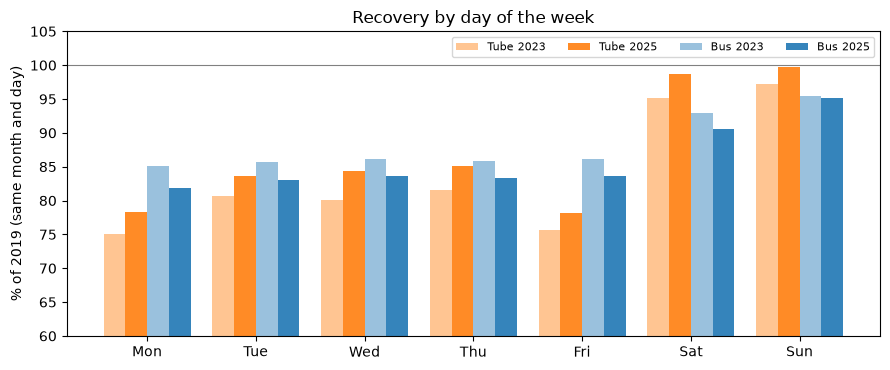

,Tube 2023,Tube 2025,Bus 2023,Bus 2025
Mon,75.1,78.3,85.1,81.8
Tue,80.7,83.6,85.7,83.0
Wed,80.1,84.3,86.1,83.6
Thu,81.5,85.1,85.8,83.3
Fri,75.6,78.1,86.2,83.7
Sat,95.1,98.7,93.0,90.5
Sun,97.2,99.8,95.4,95.2


In [3]:
dow = pd.DataFrame({y: 100 * j[j.year == y].groupby('dow')[['tube_rel', 'bus_rel']].mean().stack()
                    for y in [2023, 2025]}).unstack(1).round(1)
dow.index = DOW
dow.columns = [f'{m.split("_")[0].capitalize()} {y}' for y, m in dow.columns]
dow = dow[['Tube 2023', 'Tube 2025', 'Bus 2023', 'Bus 2025']]
dow.to_csv(B.RESULTS / 'recovery_by_day_of_week.csv', index_label='day')

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(7)
for k, (col, c) in enumerate(zip(dow.columns, ['C1', 'C1', 'C0', 'C0'])):
    ax.bar(x + (k - 1.5) * .2, dow[col], .2, color=c, alpha=.45 if '2023' in col else .9, label=col)
ax.axhline(100, color='grey', lw=.8); ax.set_xticks(x, DOW); ax.set_ylim(60, 105)
ax.set_ylabel('% of 2019 (same month and day)'); ax.legend(ncol=4, fontsize=8)
ax.set_title('Recovery by day of the week'); plt.tight_layout(); plt.show()
dow

The Tube's shortfall is a **weekday commuting** shortfall: Mondays and Fridays are furthest below
2019 (hybrid working), mid-week days are higher, and weekends are back to 2019. Buses show no such
pattern: they are about equally far below 2019 on every weekday and below it at weekends too, and
every day of the week fell between 2023 and 2025.

## 2. Trend since mid-2023

In [4]:
def trend(series, start='2023-07-01'):
    m = series[series.index >= start].resample('MS').mean().dropna().to_frame('y')
    m['t'] = np.arange(len(m)) / 12
    r = smf.ols('np.log(y) ~ t', data=m).fit(cov_type='HAC', cov_kwds={'maxlags': 3})
    lo, hi = r.conf_int().loc['t']
    return {'trend (% per year)': round(100 * r.params['t'], 2),
            '95% CI': f"{100 * lo:.2f} to {100 * hi:.2f}", 'months': len(m)}

rows = {}
for name, mask in [('all days', slice(None)), ('weekdays', j.dow < 5), ('weekends', j.dow >= 5)]:
    jj = j[mask]
    for m in ['tube', 'bus']:
        rows[(name, m.capitalize())] = trend(jj[f'{m}_rel'])
trends = pd.DataFrame(rows).T
trends.to_csv(B.RESULTS / 'recovery_trend_since_2023.csv')
trends

trend (% per year)          95% CI months
all days Tube               0.54   -0.07 to 1.15     41
         Bus               -2.23  -2.57 to -1.89     41
weekdays Tube               0.67    0.09 to 1.26     41
         Bus               -2.51  -2.80 to -2.23     41
weekends Tube               0.39   -0.64 to 1.43     41
         Bus               -1.48  -1.97 to -0.99     41

Monthly recovery index, log-linear trend from July 2023, with autocorrelation-robust (HAC)
confidence intervals.

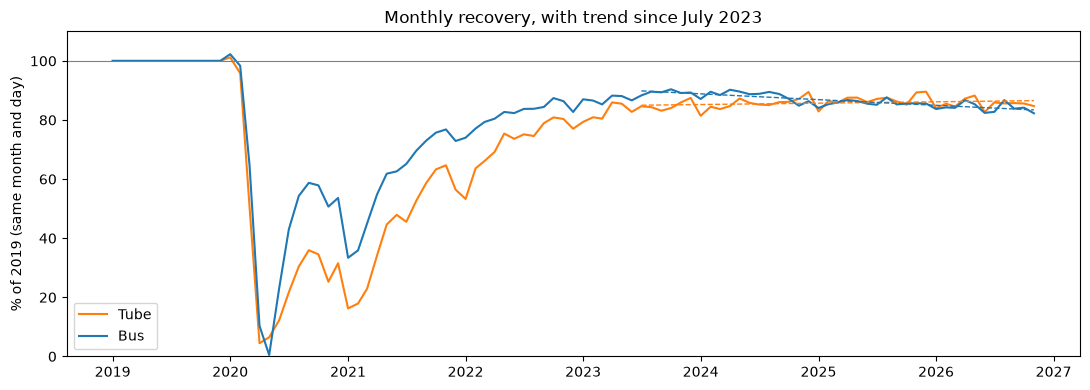

In [5]:
mth = (100 * j[['tube_rel', 'bus_rel']].resample('MS').mean())
mth.round(2).to_csv(B.RESULTS / 'recovery_monthly.csv', index_label='month')
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(mth.index, mth.tube_rel, 'C1', label='Tube')
ax.plot(mth.index, mth.bus_rel, 'C0', label='Bus')
for m, c in [('tube_rel', 'C1'), ('bus_rel', 'C0')]:
    s = mth[m][mth.index >= '2023-07-01']
    t = np.arange(len(s)) / 12
    b = np.polyfit(t, np.log(s), 1)
    ax.plot(s.index, np.exp(np.polyval(b, t)), c + '--', lw=1)
ax.axhline(100, color='grey', lw=.8); ax.set_ylim(0, 110)
ax.set_ylabel('% of 2019 (same month and day)'); ax.legend()
ax.set_title('Monthly recovery, with trend since July 2023'); plt.tight_layout(); plt.show()

## 3. When did the bus decline start?

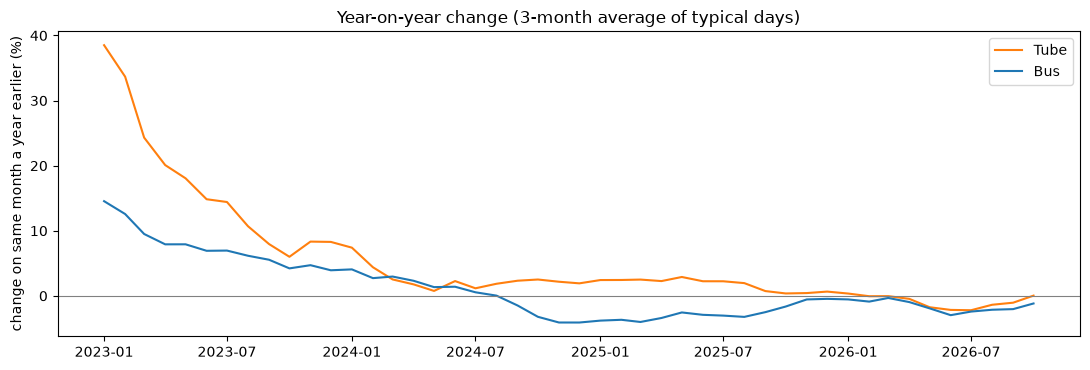

bus year-on-year change negative for three months running from September 2024
date  2024-01-01  2024-04-01  2024-07-01  2024-10-01  2025-01-01  2025-04-01  \
tube         4.8         1.6         1.8         2.2         2.5         2.5   
bus          3.2         1.7        -0.3        -3.8        -3.8        -3.0   

date  2025-07-01  2025-10-01  2026-01-01  2026-04-01  2026-07-01  2026-10-01  
tube         1.6         0.5         0.1        -1.5        -1.5         0.0  
bus         -2.9        -0.9        -0.6        -2.0        -2.2        -1.2  


In [6]:
yoy = 100 * (j[['tube', 'bus']].resample('MS').mean().pipe(lambda m: m / m.shift(12) - 1))
yoy = yoy.rolling(3, center=True).mean().loc['2023-01':]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(yoy.index, yoy.tube, 'C1', label='Tube'); ax.plot(yoy.index, yoy.bus, 'C0', label='Bus')
ax.axhline(0, color='grey', lw=.8); ax.set_ylabel('change on same month a year earlier (%)')
ax.legend(); ax.set_title('Year-on-year change (3-month average of typical days)'); plt.tight_layout(); plt.show()
first_neg = yoy.bus[(yoy.bus < 0) & (yoy.bus.shift(-1) < 0) & (yoy.bus.shift(-2) < 0)].index.min()
print(f"bus year-on-year change negative for three months running from {first_neg:%B %Y}")
print((yoy.resample('QS').mean().round(1)).loc['2024':].T)

## 4. How much do service cuts explain?

The previous notebook (`bus-demand-change.ipynb`) found, from BUSTO, that capacity on bus route-stops
served in both years fell 3.3% on weekdays between 2023-24 and 2025-26, and that demand falls about
0.6% for each 1% of capacity removed.

In [7]:
dec = pd.read_csv(B.RESULTS / 'bus_change_decomposition.csv', index_col='day type')
elasticity = 0.59   # bus-demand-change.ipynb, route-level weighted regression
expl = pd.DataFrame({
    'boardings, continuing route-stops (%)': dec['continuing route-stops (%)'],
    'capacity (%)': dec['capacity on continuing route-stops (%)'],
})
expl['explained by capacity (%)'] = (elasticity * expl['capacity (%)']).round(1)
expl['share of the fall explained'] = (expl['explained by capacity (%)'] / expl['boardings, continuing route-stops (%)']).round(2)
expl

,"boardings, continuing route-stops (%)",capacity (%),explained by capacity (%),share of the fall explained
day type,,,,
Weekday,-7.771,-3.325,-2.0,0.26
Saturday,-6.540,-2.378,-1.4,0.21
Sunday,-3.508,-0.412,-0.2,0.06


## Summary

* **Recovery has diverged.** Both modes were at about 84-88% of 2019 in 2023. Since July 2023 the Tube
  has been flat (+0.5% a year, not significant) while **buses have lost about 2.2% a year**
  (95% CI -2.6% to -1.9%). In 2025-26 buses (84-86% of 2019) fell below the Tube (86-87%), and the bus
  share of Tube + bus journeys is back to its 2019 level (58%).
* **The bus decline started in autumn 2024.** Bus journeys were still growing year on year in early 2024;
  from September 2024 they have been lower than a year earlier every month (about -3% to -4% over the
  winter of 2024-25). In 2026 the Tube has also dipped slightly below the year before (about -1.5% in
  the spring and summer).
* **Different shortfalls.** The Tube is missing weekday commuters, most on Mondays and Fridays (hybrid
  working); at weekends it is back to 2019. Buses are below 2019 on every day, weekends included, so
  their decline is not a working-from-home effect.
* **Service cuts explain about a quarter of the bus fall.** Capacity fell 3.3% on weekdays between
  2023-24 and 2025-26; at an elasticity of about 0.6 that accounts for roughly 2 of the 7.8 points lost.
  Most of the fall is fewer passengers on an unchanged service.
* **Buses are not picking up displaced Tube passengers**: on Tube strike days buses rose only 5-15% (EDA).